# S&P 500 Multi-Source Financial Database Integration & Market Visualizations

## Step 1 Import datasets and Store in a Database

#### 1.01 Load the necessary libraries

In [1]:
# Import libraries
import pandas as pd
import sqlite3


#### 1.02 Read in the CSV files for 3 cleaned and transformed datasets

In [2]:
# Using read_csv() to read 3 cleaned and transformed datasets from the local directory
# Load the dataset files to Pandas DataFrame called 'financial','index','top10'
financial= pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/The-Data-Wrangling-Workshop-master/Chapter08/Activity 8.01/Cleaned_financial_sp500.csv')
index= pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/The-Data-Wrangling-Workshop-master/Chapter08/Activity 8.01/cleaned_index.csv')
top10= pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/The-Data-Wrangling-Workshop-master/Chapter08/Activity 8.01/cleaned_top10.csv')



#### 1.03 Preview dataset structure and size

In [3]:
# Preview the structure of all three datasets
print(financial.info())
print(index.info())
print(top10.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2007 entries, 0 to 2006
Data columns (total 18 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   date                                    2007 non-null   object 
 1   firm                                    2007 non-null   object 
 2   ticker                                  2007 non-null   object 
 3   research_development                    630 non-null    float64
 4   income_before_tax                       2006 non-null   float64
 5   net_income                              2007 non-null   float64
 6   selling_general_administrative          1947 non-null   float64
 7   gross_profit                            2007 non-null   float64
 8   ebit                                    2007 non-null   float64
 9   operating_income                        2006 non-null   float64
 10  interest_expense                        1825 non-null   floa

#### 1.04 Connect to SQLite

In [4]:
# Using sqlite3 to create a DB file named "financial_data.db"
# Using connect() to connect to database
conn = sqlite3.connect("financial_data.db")



#### 1.05 Load each dataset as a table

In [5]:
# Using to_sql() to load each dataset as a table in database
financial.to_sql("financial_sp500", conn, if_exists="replace", index=False)
index.to_sql("index_data", conn, if_exists="replace", index=False)
top10.to_sql("top10_data", conn, if_exists="replace", index=False)

12550

In [6]:
# Preview first 10 rows of index_data table
preview_index = pd.read_sql("SELECT * FROM index_data LIMIT 10", conn)
print(preview_index)

   Unnamed: 0                  company symbol  weight   price   chg  %_chg
0           0                   Nvidia   NVDA    7.16  164.92  0.82   0.50
1           1                Microsoft   MSFT    6.66  503.32  1.84   0.37
2           2               Apple Inc.   AAPL    5.62  211.16 -1.25  -0.59
3           3                   Amazon   AMZN    4.25  225.02  2.76   1.24
4           4           Meta Platforms   META    3.21  717.51 -9.73  -1.34
5           5                 Broadcom   AVGO    2.30  274.38 -1.02  -0.37
6           6  Alphabet Inc. (Class A)  GOOGL    2.00  180.19  2.57   1.45
7           7  Alphabet Inc. (Class C)   GOOG    1.90  181.31  2.61   1.46
8           8       Berkshire Hathaway  BRK.B    1.83  475.86 -2.41  -0.50
9           9              Tesla, Inc.   TSLA    1.80  313.51  3.64   1.17


## Step 2 Join Datasets

#### 2.01 Makesure Primary key is unique for each table

Data cleaning for the 'financial_sp500' table

In [7]:
# Using read_sql() to write SQL to query data from the table
# Using limit 10 to preview 10 rows of financial_sp500 table
preview_df = pd.read_sql("SELECT * FROM financial_sp500 LIMIT 10", conn)

# Display 10 rows of financial_sp500 table
print(preview_df)

         date                 firm ticker  research_development  \
0  2021-09-30                   3M    MMM           482000000.0   
1  2021-06-30                   3M    MMM           514000000.0   
2  2021-03-31                   3M    MMM           520000000.0   
3  2020-12-31                   3M    MMM           449000000.0   
4  2021-09-30          A. O. Smith    AOS                   NaN   
5  2021-06-30          A. O. Smith    AOS                   NaN   
6  2021-03-31          A. O. Smith    AOS                   NaN   
7  2020-12-31          A. O. Smith    AOS                   NaN   
8  2021-09-30  Abbott Laboratories    ABT           672000000.0   
9  2021-06-30  Abbott Laboratories    ABT           654000000.0   

   income_before_tax    net_income  selling_general_administrative  \
0       1.761000e+09  1.434000e+09                    1.739000e+09   
1       1.940000e+09  1.524000e+09                    1.666000e+09   
2       1.946000e+09  1.624000e+09                  

In [8]:
# Deduplicate primary key
# Using cursor() to create a cursor object and assigned to the variable 'c' from a connection object 'conn'
c = conn.cursor()

# Using execute() method to send and execute a single SQL statement to the connected database
# Drop the table if it already exists
c.execute("DROP TABLE IF EXISTS financial_new")


# Using CREATE TABLE to create a new tabel with the only latest date of each ticker, so the table has unique Primary key 'ticker' and named 'financial_new'
c.execute("""
CREATE TABLE financial_new AS
SELECT f.*
FROM financial_sp500 f
JOIN (
    SELECT ticker, MAX(date) AS latest_date
    FROM financial_sp500
    GROUP BY ticker
) latest
ON f.ticker = latest.ticker
AND f.date = latest.latest_date;
""")

# Using commit() to save all the changes in the current connection to the database file
conn.commit()

In [9]:
# Using read_sql() to write SQL to query data from the table
preview_new = pd.read_sql("SELECT * FROM financial_new", conn)

# Preview the new table 'financial_new' with unique primary key 'ticker'
print(preview_new)

           date                 firm ticker  research_development  \
0    2021-09-30                   3M    MMM          4.820000e+08   
1    2021-09-30          A. O. Smith    AOS                   NaN   
2    2021-09-30  Abbott Laboratories    ABT          6.720000e+08   
3    2021-09-30               Abbvie   ABBV          1.655000e+09   
4    2021-09-30              Abiomed   ABMD          4.104100e+07   
..          ...                  ...    ...                   ...   
497  2021-06-30          Yum! Brands    YUM                   NaN   
498  2021-07-03   Zebra Technologies   ZBRA          1.410000e+08   
499  2021-06-30        Zimmer Biomet    ZBH          1.805000e+08   
500  2021-06-30        Zions Bancorp   ZION                   NaN   
501  2021-06-30               Zoetis    ZTS          1.200000e+08   

     income_before_tax    net_income  selling_general_administrative  \
0         1.761000e+09  1.434000e+09                    1.739000e+09   
1         1.664000e+08  1.3

Data cleaning for the 'top10_data' table

In [10]:
# Preview 10 rows of top10_data table
preview_df2 = pd.read_sql("SELECT * FROM top10_data LIMIT 10", conn)

print(preview_df2)

   Unnamed: 0 symbol        date    open    high     low   close     volume  \
0           0   NVDA  2025-07-25  173.61  174.72  172.96  173.50  122316792   
1           1   NVDA  2025-07-24  172.44  173.83  171.30  173.74  128984628   
2           2   NVDA  2025-07-23  169.53  171.26  167.97  170.78  154082200   
3           3   NVDA  2025-07-22  171.34  171.39  164.58  167.03  193114327   
4           4   NVDA  2025-07-21  172.75  173.38  171.00  171.38  123126136   
5           5   NVDA  2025-07-18  173.64  174.25  171.26  172.41  146456416   
6           6   NVDA  2025-07-17  172.02  174.16  170.83  173.00  160841119   
7           7   NVDA  2025-07-16  171.06  171.75  168.90  171.37  158831509   
8           8   NVDA  2025-07-15  171.19  172.40  169.20  170.70  230627400   
9           9   NVDA  2025-07-14  165.37  165.49  162.02  164.07  136975800   

   change  changepercent    vwap  
0   -0.11          -0.06  173.70  
1    1.30           0.75  172.83  
2    1.25           0.74 

In [11]:
# Using cursor() to create a cursor object and assigned to the variable 'c' from a connection object 'conn'
c = conn.cursor()

# Using execute() method to send and execute a single SQL statement to the connected database
# Drop the table if it already exists
c.execute("DROP TABLE IF EXISTS top10_new")


# Using CREATE TABLE to create a new tabel with the only latest date of each symbol, so the table has unique Primary key 'symbol' and named 'top10_new'
c.execute("""
CREATE TABLE top10_new AS
SELECT t.*
FROM top10_data t
JOIN (
    SELECT symbol, MAX(date) AS latest_date
    FROM top10_data
    GROUP BY symbol
) latest
ON t.symbol = latest.symbol
AND t.date = latest.latest_date;
""")

# Using commit() to save all the changes in the current connection to the database file
conn.commit()

In [12]:
# Using read_sql() to write SQL to query data from the table
preview_topnew = pd.read_sql("SELECT * FROM top10_new", conn)

# Preview the new table 'top_new' with unique primary key 'symbol'
print(preview_topnew)

   Unnamed: 0 symbol        date    open    high     low   close     volume  \
0           0   NVDA  2025-07-25  173.61  174.72  172.96  173.50  122316792   
1        1255   MSFT  2025-07-25  512.47  518.29  510.36  513.71   19125699   
2        2510   AAPL  2025-07-25  214.70  215.24  213.40  213.88   40268781   
3        3765   AMZN  2025-07-25  232.22  232.48  231.18  231.44   28712095   
4        5020   META  2025-07-25  716.92  720.65  711.90  712.68    8271698   
5        6275  GOOGL  2025-07-25  191.98  194.33  191.26  193.18   39785863   
6        7530   TSLA  2025-07-25  308.74  323.63  308.01  316.06  148227027   
7        8785    JPM  2025-07-25  296.70  298.90  295.96  298.62    5918875   
8       10040    WMT  2025-07-25   96.84   97.65   96.53   97.47   12868466   
9       11295      V  2025-07-25  354.00  357.65  353.01  357.04    3915781   

   change  changepercent    vwap  
0   -0.11          -0.06  173.70  
1    1.25           0.24  513.71  
2   -0.82          -0.38 

#### 2.02 Create a joined dataset

In [13]:
# Using SQL to select all from 3 tables and left join them together on primary key stock symbol in SQLite
query = """
SELECT i.*, f.*,t.*
FROM index_data i
LEFT JOIN financial_new f ON i.symbol = f.ticker
LEFT JOIN top10_new t ON i.symbol = t.symbol
"""

# Using read_sql() to run the SQL query against the SQLite conn connection
# Loads the results directly into a Pandas DataFrame named 'merged_index'
merged_index = pd.read_sql(query, conn)



In [14]:
# Using to_csv() to save the merged dataset to CSV file
merged_index.to_csv("merged_dataset.csv", index=False)


#### 2.03 Check Date Types and Structure for The Merged Dataset

In [15]:
# Preview the new merged dataset
print(merged_index.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 36 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Unnamed: 0                              503 non-null    int64  
 1   company                                 503 non-null    object 
 2   symbol                                  503 non-null    object 
 3   weight                                  503 non-null    float64
 4   price                                   503 non-null    float64
 5   chg                                     503 non-null    float64
 6   %_chg                                   503 non-null    float64
 7   date                                    433 non-null    object 
 8   firm                                    433 non-null    object 
 9   ticker                                  433 non-null    object 
 10  research_development                    132 non-null    float6

In [16]:
# Using .duplicated() to check if any duplicates for the primary key 'symbol'
duplicates = merged_index[merged_index.duplicated(subset=['symbol'])]

# Display duplicated if any exist
print(duplicates)

# No duplicate for primary key symbol

Empty DataFrame
Columns: [Unnamed: 0, company, symbol, weight, price, chg, %_chg, date, firm, ticker, research_development, income_before_tax, net_income, selling_general_administrative, gross_profit, ebit, operating_income, interest_expense, income_tax_expense, total_revenue, total_operating_expenses, cost_of_revenue, total_other_income_expense_net, net_income_from_continuing_ops, net_income_applicable_to_common_shares, Unnamed: 0, symbol, date, open, high, low, close, volume, change, changepercent, vwap]
Index: []

[0 rows x 36 columns]


In [17]:
# Preview the first 20 rows of the new merged dataset
print(merged_index.head(20))


    Unnamed: 0                  company  symbol  weight    price    chg  \
0            0                   Nvidia    NVDA    7.16   164.92   0.82   
1            1                Microsoft    MSFT    6.66   503.32   1.84   
2            2               Apple Inc.    AAPL    5.62   211.16  -1.25   
3            3                   Amazon    AMZN    4.25   225.02   2.76   
4            4           Meta Platforms    META    3.21   717.51  -9.73   
5            5                 Broadcom    AVGO    2.30   274.38  -1.02   
6            6  Alphabet Inc. (Class A)   GOOGL    2.00   180.19   2.57   
7            7  Alphabet Inc. (Class C)    GOOG    1.90   181.31   2.61   
8            8       Berkshire Hathaway   BRK.B    1.83   475.86  -2.41   
9            9              Tesla, Inc.    TSLA    1.80   313.51   3.64   
10          10           Jpmorgan Chase     JPM    1.42   286.86  -1.33   
11          11                  Walmart     WMT    1.34    94.40  -0.46   
12          12           

## Step 3 Human readable dataset

In [18]:
# Using .copy() to create a copy of the dataset without altering the original DataFrame
merged_new= merged_index.copy()

#### 3.01 Check the Data Types and Structure

In [19]:
# Display the data types of the data set
print(merged_new.dtypes)


Unnamed: 0                                  int64
company                                    object
symbol                                     object
weight                                    float64
price                                     float64
chg                                       float64
%_chg                                     float64
date                                       object
firm                                       object
ticker                                     object
research_development                      float64
income_before_tax                         float64
net_income                                float64
selling_general_administrative            float64
gross_profit                              float64
ebit                                      float64
operating_income                          float64
interest_expense                          float64
income_tax_expense                        float64
total_revenue                             float64


In [20]:
# Preview the first 5 rows of the data set
print(merged_new.head())

   Unnamed: 0         company  symbol  weight   price   chg  %_chg  \
0           0          Nvidia    NVDA    7.16  164.92  0.82   0.50   
1           1       Microsoft    MSFT    6.66  503.32  1.84   0.37   
2           2      Apple Inc.    AAPL    5.62  211.16 -1.25  -0.59   
3           3          Amazon    AMZN    4.25  225.02  2.76   1.24   
4           4  Meta Platforms    META    3.21  717.51 -9.73  -1.34   

         date       firm ticker  ...  symbol        date    open    high  \
0  2021-08-01     Nvidia   NVDA  ...    NVDA  2025-07-25  173.61  174.72   
1  2021-06-30  Microsoft   MSFT  ...    MSFT  2025-07-25  512.47  518.29   
2  2021-06-26      Apple   AAPL  ...    AAPL  2025-07-25  214.70  215.24   
3  2021-06-30     Amazon   AMZN  ...    AMZN  2025-07-25  232.22  232.48   
4        None       None   None  ...    META  2025-07-25  716.92  720.65   

      low   close       volume  change  changepercent    vwap  
0  172.96  173.50  122316792.0   -0.11          -0.06  173

In [21]:
# Using .drop() to drop all column that without header, likely an index column from CSV export
merged_new.drop(columns=['Unnamed: 0'], inplace=True)


In [22]:
# Display the data types of the updated dataset
print(merged_new.dtypes)

# Columns that without header got dropped

company                                    object
symbol                                     object
weight                                    float64
price                                     float64
chg                                       float64
%_chg                                     float64
date                                       object
firm                                       object
ticker                                     object
research_development                      float64
income_before_tax                         float64
net_income                                float64
selling_general_administrative            float64
gross_profit                              float64
ebit                                      float64
operating_income                          float64
interest_expense                          float64
income_tax_expense                        float64
total_revenue                             float64
total_operating_expenses                  float64


#### 3.02 Convert Numeric Columns to Readable Format

In [23]:
# Using .copy() to create a copy of the dataset without altering the original DataFrame
merged_readable= merged_new.copy()

In [24]:
# Using .apply() to format integer volume with commas
merged_readable['volume'] = merged_readable['volume'].apply(lambda x: f"{x:,}")


In [25]:
# Using .apply() to format price columns with '$' and percentage columns with '%'
merged_readable['open'] = merged_readable['open'].apply(lambda x: f"${x:,.2f}")
merged_readable['high'] = merged_readable['high'].apply(lambda x: f"${x:,.2f}")
merged_readable['low'] = merged_readable['low'].apply(lambda x: f"${x:,.2f}")
merged_readable['close'] = merged_readable['close'].apply(lambda x: f"${x:,.2f}")
merged_readable['change'] = merged_readable['change'].apply(lambda x: f"${x:,.2f}")
merged_readable['vwap'] = merged_readable['vwap'].apply(lambda x: f"${x:,.2f}")
merged_readable['price'] = merged_readable['price'].apply(lambda x: f"${x:,.2f}")
merged_readable['chg'] = merged_readable['chg'].apply(lambda x: f"${x:,.2f}")
merged_readable['changepercent'] = merged_readable['changepercent'].apply(lambda x: f"{x:.2f}%")
merged_readable['%_chg'] = merged_readable['%_chg'].apply(lambda x: f"{x:.2f}%")
merged_readable['weight'] = merged_readable['weight'].apply(lambda x: f"{x:.2f}%")

In [26]:
# Define a function to convert large scientific numbers to readable format with symbols $ (like $ 1.43B)
# Using .2f to round numeric values with two decimal places for clarity
def format_money(val):
    if pd.isnull(val):
        return ''
    elif abs(val) >= 1e9:
        return f"${val/1e9:.2f}B"
    elif abs(val) >= 1e6:
        return f"${val/1e6:.2f}M"
    else:
        return f"${val:,.0f}"


In [27]:
# Select all the large scientific numbers columns 
columns_to_format = [
'research_development',
'income_before_tax',
'net_income',
'selling_general_administrative',
'gross_profit',
'ebit',
'operating_income',
'interest_expense',
'income_tax_expense',
'total_revenue',
'total_operating_expenses',
'cost_of_revenue',
'total_other_income_expense_net',
'net_income_from_continuing_ops',
'net_income_applicable_to_common_shares'
]


# Apply the format function to the selected large scientific numbers columns 
for col in columns_to_format:
    merged_readable[col] = merged_readable[col].apply(format_money)

# Preview the first 5 rows of the formated data set
print(merged_readable.head())

          company symbol weight    price     chg   %_chg        date  \
0          Nvidia   NVDA  7.16%  $164.92   $0.82   0.50%  2021-08-01   
1       Microsoft   MSFT  6.66%  $503.32   $1.84   0.37%  2021-06-30   
2      Apple Inc.   AAPL  5.62%  $211.16  $-1.25  -0.59%  2021-06-26   
3          Amazon   AMZN  4.25%  $225.02   $2.76   1.24%  2021-06-30   
4  Meta Platforms   META  3.21%  $717.51  $-9.73  -1.34%        None   

        firm ticker research_development  ... symbol        date     open  \
0     Nvidia   NVDA               $1.25B  ...   NVDA  2025-07-25  $173.61   
1  Microsoft   MSFT               $5.69B  ...   MSFT  2025-07-25  $512.47   
2      Apple   AAPL               $5.72B  ...   AAPL  2025-07-25  $214.70   
3     Amazon   AMZN              $11.79B  ...   AMZN  2025-07-25  $232.22   
4       None   None                       ...   META  2025-07-25  $716.92   

      high      low    close         volume  change changepercent     vwap  
0  $174.72  $172.96  $173.5

In [28]:
# Preview the structure of the formated dataset
print(merged_readable.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 34 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   company                                 503 non-null    object
 1   symbol                                  503 non-null    object
 2   weight                                  503 non-null    object
 3   price                                   503 non-null    object
 4   chg                                     503 non-null    object
 5   %_chg                                   503 non-null    object
 6   date                                    433 non-null    object
 7   firm                                    433 non-null    object
 8   ticker                                  433 non-null    object
 9   research_development                    503 non-null    object
 10  income_before_tax                       503 non-null    object
 11  net_in

#### 3.03 Rename columns name to more readable name

In [29]:
# Using .rename() to rename columns to more readable format
merged_readable.rename(columns={
    'symbol': 'Symbol',
    'date': 'Date',
    'open': 'Open($)',
    'high': 'High($)',
    'low': 'Low($)',
    'close': 'Close($)',
    'volume': 'Volume',
    'change': 'Change($)',
    'changepercent': 'Change(%)',
    'vwap': 'VWAP($)',
    'company':'Company',
    'weight':'Weight(%)', 
    'price':'Price($)', 
    'chg':'Change($)', 
    '%_chg':'Change(%)',
    'firm':'Firm',
    'ticker':'Ticker'
}, inplace=True)


In [30]:
# Preview the first 5 rows of the formated dataset
print(merged_readable.head())

          Company Symbol Weight(%) Price($) Change($) Change(%)        Date  \
0          Nvidia   NVDA     7.16%  $164.92     $0.82     0.50%  2021-08-01   
1       Microsoft   MSFT     6.66%  $503.32     $1.84     0.37%  2021-06-30   
2      Apple Inc.   AAPL     5.62%  $211.16    $-1.25    -0.59%  2021-06-26   
3          Amazon   AMZN     4.25%  $225.02     $2.76     1.24%  2021-06-30   
4  Meta Platforms   META     3.21%  $717.51    $-9.73    -1.34%        None   

        Firm Ticker research_development  ... Symbol        Date  Open($)  \
0     Nvidia   NVDA               $1.25B  ...   NVDA  2025-07-25  $173.61   
1  Microsoft   MSFT               $5.69B  ...   MSFT  2025-07-25  $512.47   
2      Apple   AAPL               $5.72B  ...   AAPL  2025-07-25  $214.70   
3     Amazon   AMZN              $11.79B  ...   AMZN  2025-07-25  $232.22   
4       None   None                       ...   META  2025-07-25  $716.92   

   High($)   Low($) Close($)         Volume Change($) Change(%

## Step 4 Data types transformations before Visualizations

#### 4.01 Convert date Column to datetime Format

In [31]:
#  Using .copy() to create a copy of the dataset without altering the original DataFrame
merged_visual= merged_new.copy()

# Review data frame 'merged_visual'
print (merged_visual.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 34 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   company                                 503 non-null    object 
 1   symbol                                  503 non-null    object 
 2   weight                                  503 non-null    float64
 3   price                                   503 non-null    float64
 4   chg                                     503 non-null    float64
 5   %_chg                                   503 non-null    float64
 6   date                                    433 non-null    object 
 7   firm                                    433 non-null    object 
 8   ticker                                  433 non-null    object 
 9   research_development                    132 non-null    float64
 10  income_before_tax                       432 non-null    float6

In [32]:
# Due to the duplicate column names (symbol and date appear twice) 
# Need to rename the second 'symbol' and 'date' to 'symbol2' and 'date2' by their column position
cols = merged_visual.columns.tolist()

# Rename column name by index 24 (second 'symbol') and 25 (second 'date') 
cols[24] = 'symbol2'
cols[25] = 'date2'
merged_visual.columns = cols

# Display the updated column names 
print (merged_visual.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 34 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   company                                 503 non-null    object 
 1   symbol                                  503 non-null    object 
 2   weight                                  503 non-null    float64
 3   price                                   503 non-null    float64
 4   chg                                     503 non-null    float64
 5   %_chg                                   503 non-null    float64
 6   date                                    433 non-null    object 
 7   firm                                    433 non-null    object 
 8   ticker                                  433 non-null    object 
 9   research_development                    132 non-null    float64
 10  income_before_tax                       432 non-null    float6

In [33]:
# Using .to_datetime() to convert 'date' and 'date2' to datetime object
merged_visual['date'] = pd.to_datetime(merged_visual['date'])
merged_visual['date2'] = pd.to_datetime(merged_visual['date2'])

In [34]:
# Review updated data frame 'merged_visual'
print (merged_visual.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 34 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   company                                 503 non-null    object        
 1   symbol                                  503 non-null    object        
 2   weight                                  503 non-null    float64       
 3   price                                   503 non-null    float64       
 4   chg                                     503 non-null    float64       
 5   %_chg                                   503 non-null    float64       
 6   date                                    433 non-null    datetime64[ns]
 7   firm                                    433 non-null    object        
 8   ticker                                  433 non-null    object        
 9   research_development                    132 non-null  

In [35]:
# Display the first 10 rows of the updated data frame 'merged_visual'
print (merged_visual.head(10))

                   company symbol  weight   price   chg  %_chg       date  \
0                   Nvidia   NVDA    7.16  164.92  0.82   0.50 2021-08-01   
1                Microsoft   MSFT    6.66  503.32  1.84   0.37 2021-06-30   
2               Apple Inc.   AAPL    5.62  211.16 -1.25  -0.59 2021-06-26   
3                   Amazon   AMZN    4.25  225.02  2.76   1.24 2021-06-30   
4           Meta Platforms   META    3.21  717.51 -9.73  -1.34        NaT   
5                 Broadcom   AVGO    2.30  274.38 -1.02  -0.37 2021-08-01   
6  Alphabet Inc. (Class A)  GOOGL    2.00  180.19  2.57   1.45 2021-06-30   
7  Alphabet Inc. (Class C)   GOOG    1.90  181.31  2.61   1.46 2021-06-30   
8       Berkshire Hathaway  BRK.B    1.83  475.86 -2.41  -0.50        NaT   
9              Tesla, Inc.   TSLA    1.80  313.51  3.64   1.17 2021-03-31   

                 firm ticker  research_development  ...  symbol2      date2  \
0              Nvidia   NVDA          1.245000e+09  ...     NVDA 2025-07-

#### 4.02 Check Missing Values

In [36]:
# Using .isnull() to check missing values
missing = merged_visual.isnull().sum()

# Display missing value columns and counts
print("Total missing value column names and volumes:")
print(missing[missing > 0].sort_values(ascending=False))



Total missing value column names and volumes:
vwap                                      493
volume                                    493
symbol2                                   493
date2                                     493
open                                      493
high                                      493
low                                       493
close                                     493
change                                    493
changepercent                             493
research_development                      371
interest_expense                          109
selling_general_administrative             88
net_income_applicable_to_common_shares     71
operating_income                           71
income_before_tax                          71
net_income_from_continuing_ops             71
date                                       70
total_other_income_expense_net             70
firm                                       70
total_operating_expenses          

In [37]:
# Since the third dataset only has the top 10 available stock symbols based on weight, we can see 493 missing values when we use a left join to join the top 10 dataset

#### 4.03 View Summary Statistics

In [38]:
# Using .describe() to get a overview of value distributions
print(merged_visual.describe())


           weight        price         chg       %_chg  \
count  503.000000   503.000000  503.000000  503.000000   
mean     0.198648   224.726024   -1.594493   -0.758767   
min      0.000000     0.000000  -57.480000   -5.730000   
25%      0.040000    70.465000   -2.070000   -1.375000   
50%      0.070000   131.170000   -0.810000   -0.690000   
75%      0.150000   235.995000   -0.090000   -0.110000   
max      7.160000  7632.240000   11.620000    4.150000   
std      0.597615   486.752768    4.322961    1.217939   

                                date  research_development  income_before_tax  \
count                            433          1.320000e+02       4.320000e+02   
mean   2021-07-09 02:29:39.214780672          7.148179e+08       1.172184e+09   
min              2021-02-28 00:00:00          1.290000e+07      -2.246000e+09   
25%              2021-06-30 00:00:00          6.814675e+07       2.069250e+08   
50%              2021-06-30 00:00:00          2.231500e+08       4.48400

## Step 5 Create Five Visualizations with the Merged Dataset

In [39]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

### Visualizations 1: Bar Chart for the biggest companies by weight

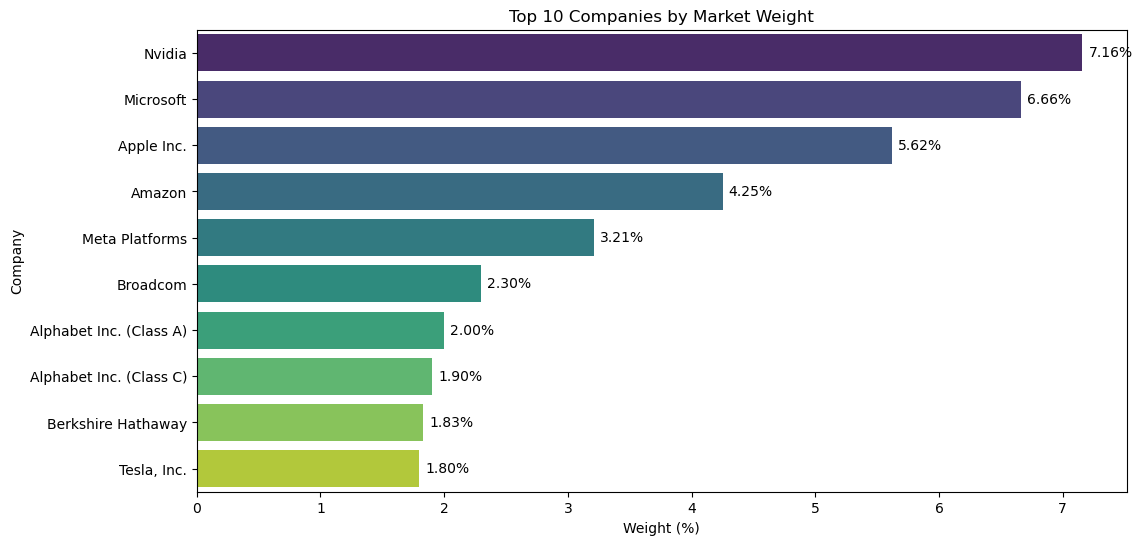

In [40]:
# Shows the top 10 biggest companies by weight to get a sense of market influence
# Using sort_values() to sort the top 10 companies by market weight in descending order
top10_weight = merged_visual.sort_values('weight', ascending=False).head(10)

# Using sns.barplot() to plot a bar chart with weight and company 
plt.figure(figsize=(12,6))
sns.barplot(data=top10_weight, x='weight', y='company', hue='company', palette='viridis')
# Add percentage labels to the right side of each bar
for index, row in top10_weight.iterrows():
    plt.text(
        row['weight'] + 0.05,      
        index - top10_weight.index.min(),  
        f"{row['weight']:.2f}%",  
        color='black',
        va='center'
    )
plt.title('Top 10 Companies by Market Weight')
plt.xlabel('Weight (%)')
plt.ylabel('Company')
# Display the bar chart
plt.show()

### Visualizations 2: Correlation heatmap of selected financial metrics

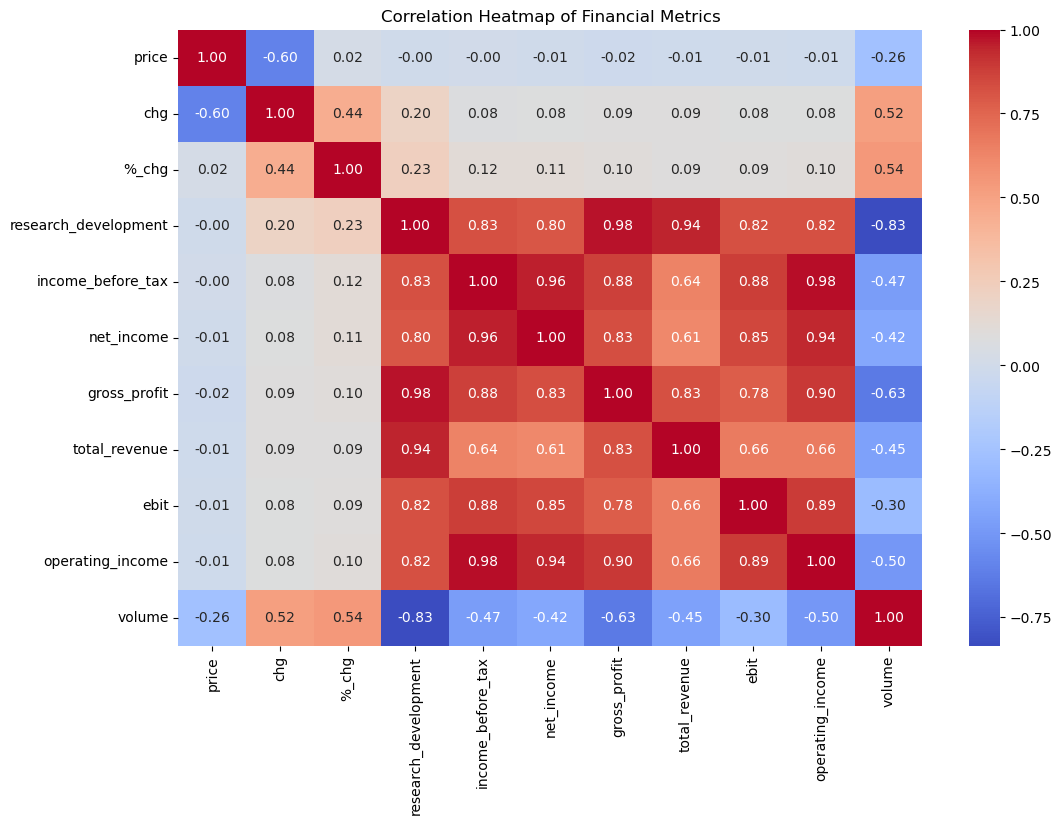

In [41]:
# Displays correlations between key financial columns (The heatmap financial metrics data span across all 3 dataset tables)
# Using sns.heatmap() to create a correlation heatmap of selected financial metrics
financial_metrics = ['price', 'chg', '%_chg', 'research_development', 'income_before_tax', 'net_income', 'gross_profit', 'total_revenue','ebit', 'operating_income','volume']
plt.figure(figsize=(12,8))
corr = merged_visual[financial_metrics].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Financial Metrics')
# Display the heatmap
plt.show()

### Visualizations 3: Scatter plot for R&D spending and stock price

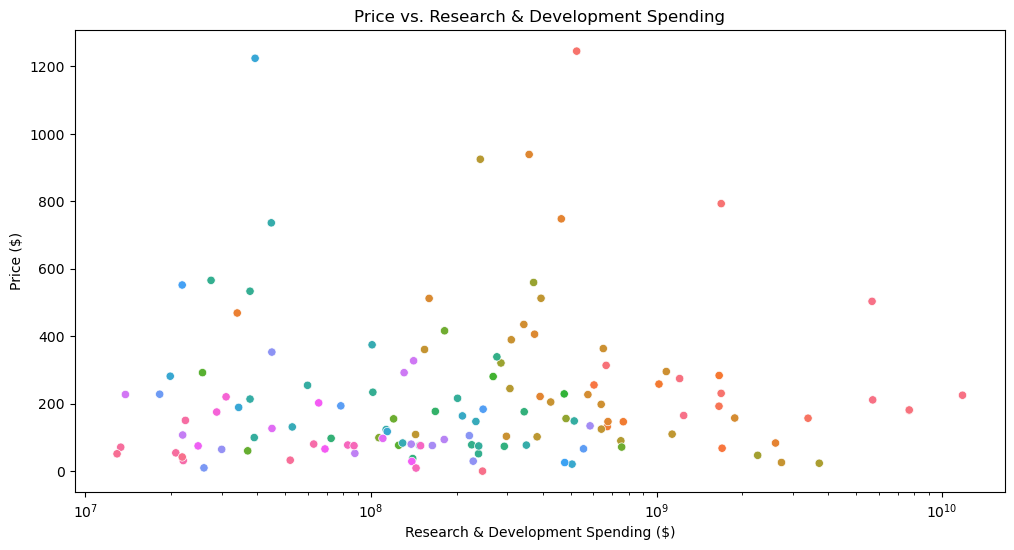

In [42]:
# Visualizes if R&D spending relates to stock price. (The scatter plot financial metrics data span across 2 of the dataset tables )
# Using sns.scatterplot() to create a scatter plot for Price vs. Research & Development spending
plt.figure(figsize=(12,6))
sns.scatterplot(data=merged_visual, x='research_development', y='price', hue='company', legend=False)
plt.title('Price vs. Research & Development Spending')
plt.xlabel('Research & Development Spending ($)')
plt.ylabel('Price ($)')
plt.xscale('log') 
# Display the scatter plot
plt.show()

# Scatter plot shows no relation between Price and Research & Development Spending, which is expected from previous heatmap showing 0.00 correlations between these two metrics


### Visualizations 4: Histogram chart of Distribution of Stock Price change in Percentage

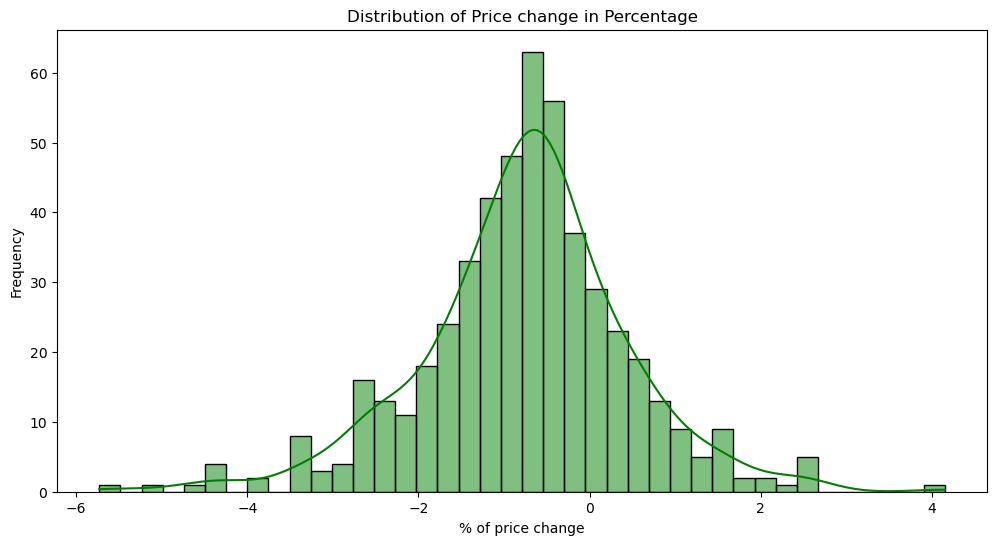

In [43]:
# Understand how the percentage changes are distributed of the stock price
# Using sns.histplot() to create a histogram chart to show the distribution of % Change (%_chg) 
plt.figure(figsize=(12,6))
sns.histplot(merged_visual['%_chg'].dropna(), bins=40, kde=True, color='green')
plt.title('Distribution of Price change in Percentage')
plt.xlabel('% of price change')
plt.ylabel('Frequency')
# Display the histogram chart
plt.show()

### Visualizations 5: Pie chart of Total Gross Profit for Top 10 Companies by Market Weight

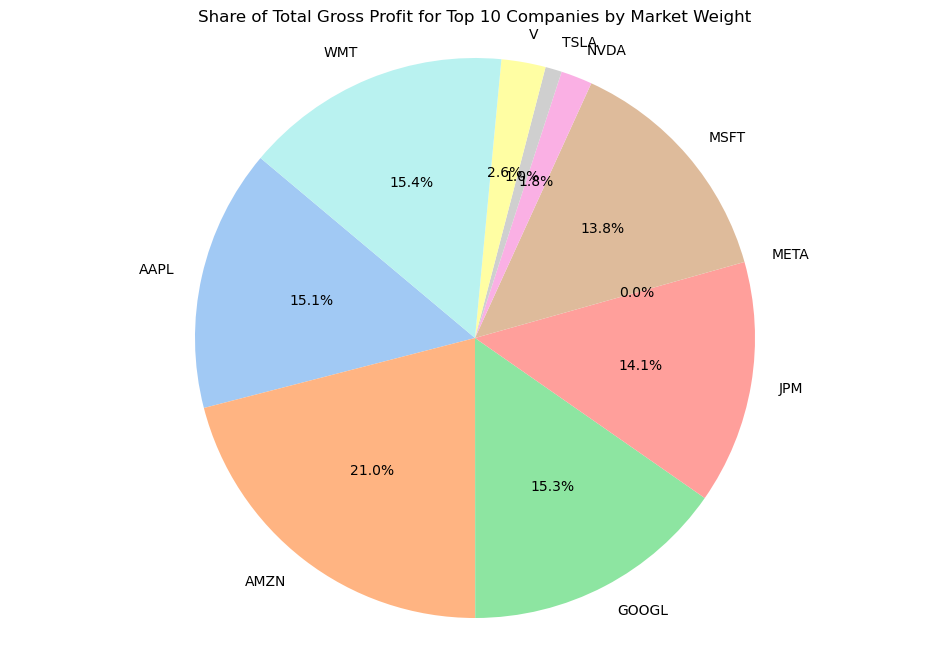

In [44]:
# Understand the proportional relationship of Total Gross Profit between the top 10 Companies by Market Weight (The pie chart financial metrics data span across 2 of the dataset tables )
# Using plt.pie() to create a pie chart to show the proportion of Gross Profit for each company
gross_profit_share = merged_visual.groupby('symbol2')['gross_profit'].sum()

plt.figure(figsize=(12,8))
plt.pie(
    gross_profit_share, 
    labels=gross_profit_share.index,        
    autopct='%1.1f%%',      
    startangle=140, 
    colors=sns.color_palette('pastel')
)
plt.title('Share of Total Gross Profit for Top 10 Companies by Market Weight')
plt.axis('equal') 
# Display the pie chart
plt.show()

### Visualizations 6: Scatter plot of Volume and Price change in % for Top 10 Companies by Market Weight

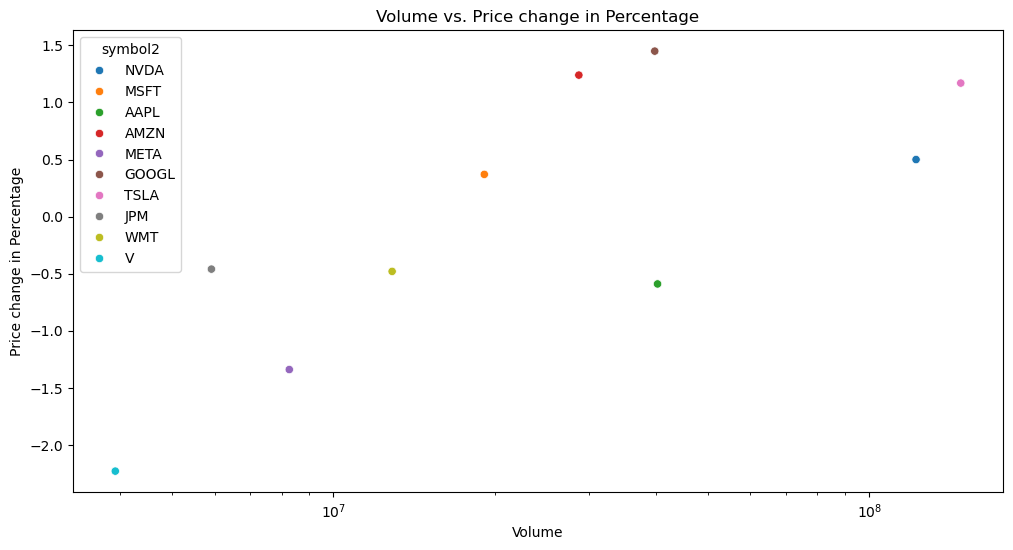

In [45]:
# Scatter plot to visualizes the relationship between the volume and the price change in % for Top 10 Companies by Market Weight (The Scatter plot financial metrics data span across 2 of the dataset tables)
# Using sns.scatterplot() to create a scatter plot for Volume vs. Price change in %
plt.figure(figsize=(12,6))
sns.scatterplot(data=merged_visual,  x='volume', y='%_chg', hue='symbol2', legend=True)
plt.title('Volume vs. Price change in Percentage')
plt.xlabel('Volume')
plt.ylabel('Price change in Percentage')
plt.xscale('log')  
# Display the scatter plot
plt.show()

## Step 6 Human readable dataset

#### 8.01 Display the Human readable dataset

In [46]:
# Display the cleaned, human readable format data set
print(merged_readable)

                   Company Symbol Weight(%) Price($) Change($) Change(%)  \
0                   Nvidia   NVDA     7.16%  $164.92     $0.82     0.50%   
1                Microsoft   MSFT     6.66%  $503.32     $1.84     0.37%   
2               Apple Inc.   AAPL     5.62%  $211.16    $-1.25    -0.59%   
3                   Amazon   AMZN     4.25%  $225.02     $2.76     1.24%   
4           Meta Platforms   META     3.21%  $717.51    $-9.73    -1.34%   
..                     ...    ...       ...      ...       ...       ...   
498      Mohawk Industries    MHK     0.01%  $112.53    $-1.30    -1.14%   
499    News Corp (Class B)    NWS     0.01%   $34.29    $-0.16    -0.46%   
500  Caesars Entertainment    CZR     0.01%   $30.03    $-1.48    -4.70%   
501         Enphase Energy   ENPH     0.01%   $41.86    $-1.12    -2.59%   
502       Juniper Networks   JNPR     0.00%    $0.00     $0.00     0.00%   

           Date                   Firm Ticker research_development  ...  \
0    2021-08

#### 8.02 Export and save the Human readable dataset

In [47]:
# Using .to_excel() to save the readable dataset to excel file
merged_readable.to_excel('readable_merged.xlsx')

## Step 7 Ethical implications

* Combining three separate datasets into one cohesive dataset for analysis and visualizations. These datasets had been individually cleaned and transformed in earlier assignments. Still, integration required additional steps to ensure consistency and usability. <br> 
* One of the primary challenges was that two datasets contained the same stock symbols with multiple entries for different dates. To create a unique key for each stock, only the most recent date's record for each symbol was retained. This step ensured that duplicate keys would not create ambiguity in joins or aggregations. <br>
* Data wrangling steps included importing the dataset, connecting to SQLite, loading each dataset as a table, removing duplicate keys, creating a joined dataset, standardizing column names, formatting numerical values for readability, converting the datatype object to datetime, and identifying missing values. Additionally, data visualizations were conducted on the dataset. These changes aimed to enhance usability while preserving the dataset's integrity.<br> 
* The merged dataset is publicly available and intended for educational use. No personally identifiable or proprietary data was involved, which reduces regulatory concerns. However, since the financial data may be used for decision-making, it is important to avoid misrepresentation due to transformation errors. <br>
* A key risk introduced by removing older date records could impact future reproducibility and limit the ability to analyze historical patterns. Any analysis based on incomplete or misaligned timeframes could potentially mislead decision-making, especially if presented without context about the data's limitations. <br>
* Assumptions were made regarding the latest data being the most relevant for analysis. However, this assumption might not hold true for all use cases. Additionally, merging datasets with mismatched time ranges could inadvertently create analytical bias, as more recent data might reflect different market conditions than older data. <br>
* The merged datasets were sourced from prior assignments. Verifying their credibility by tracing them back to reputable, transparent sources is essential. Ethical acquisition involves ensuring that the data is publicly available, legally obtained, and used consistently with its intended purpose. <br>
* To mitigate ethical concerns, documentation of every transformation should be maintained, along with a clear explanation of the reasoning. Analysts should disclose time range mismatches and any assumptions made during cleaning to stakeholders, ensuring transparency. Retaining a full historical version alongside the cleaned dataset can preserve reproducibility and allow future alternative analyses. <br>
